# Cruce | INPC y cadena del maíz: precios en pesos constantes

## 1 | Pregunta y decisiones

**¿Cambian las conclusiones de la Historia 1 (quién paga el maíz caro) cuando se descuenta la inflación general?**

La libreta `05-mg-cadena-maiz-tortilla` compara precios en pesos corrientes. Aquí se repite la comparación en pesos constantes de 2025.

Decisiones de análisis:

- **Deflactor:** promedio anual del INPC general (base 2a quincena de julio de 2018 = 100). Factor del año *t* = INPC promedio 2025 / INPC promedio de *t*.
- **Eslabones:** productor (DGSIAP), mayorista (SNIIM, cinco centrales) y tortilla (PROFECO, tortillerías), igual que en la Historia 1.
- **Fases:** subida 2020 → 2023 y bajada 2023 → 2025, las mismas de la Historia 1.
- **Tortilla:** el dato anual usa solo los meses con precio; como control se deflacta mes a mes y luego se promedia.
- **Límite:** el INPC general no es el índice de precios de los alimentos ni de la tortilla.

## 2 | Datos y deflactor

In [1]:
# Importamos herramientas y fijamos una presentación común.
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from IPython.display import display, Markdown

from rendimiento_bachoco.features import transmision_asimetrica

AZUL, OCRE, GRIS, VERDE, ROJO = "#1f4e79", "#c27c0e", "#7f8c8d", "#2e7d5b", "#a93226"
COLORES = {"productor": "#3f8f4f", "mayorista": "#c9913d", "tortilla": "#c0392b"}
ETIQUETAS = {"productor": "Productor", "mayorista": "Mayorista", "tortilla": "Tortilla"}
ESLABONES = ["productor", "mayorista", "tortilla"]
sns.set_theme(style="whitegrid", context="notebook", font_scale=0.95)
plt.rcParams.update({
    "figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 12,
})
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)

raiz = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "data" / "processed" / "inpc_mensual.csv").is_file()),
    None,
)
if raiz is None:
    raise FileNotFoundError("Abre la libreta dentro del repositorio con los datos procesados.")
FIG = raiz / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

def guardar(fig, nombre):
    fig.savefig(FIG / f"inpc_cruce_{nombre}.png", dpi=150, bbox_inches="tight")

H = {}  # cifras que se reutilizan en la síntesis
ANIO_BASE, BASE, PICO, FINAL = 2025, 2020, 2023, 2025

2026-11-14 10:31:10.508 | INFO     | rendimiento_bachoco.config:<module>:15 - La ruta de PROJ_ROOT es: /Users/manuel_gortarez/Projects/Rendimiento_Bursatil_Sector_Agropecuario


In [2]:
# Cargamos la cadena anual, el INPC y el precio mensual de la tortilla.
cadena = pd.read_csv(raiz / "data/processed/cadena_maiz_anual.csv")
inpc = pd.read_csv(raiz / "data/processed/inpc_mensual.csv", parse_dates=["fecha"]).set_index("fecha").sort_index()
tort_todo = pd.read_csv(raiz / "data/processed/precio_tortilla_mensual.csv", parse_dates=["fecha"])
tort = (tort_todo[(tort_todo["nivel"] == "nacional") & (tort_todo["giro"] == "tortilleria")]
        .set_index("fecha")["precio_mediana_mxn_kg"].sort_index())

cuenta = inpc.groupby(inpc.index.year)["indice"].size()
assert (cuenta.loc[cadena["anio"]] == 12).all(), "Hay años de la cadena con INPC incompleto"
ipc_anual = inpc.groupby(inpc.index.year)["indice"].mean()
cadena = cadena[["anio", *ESLABONES]].copy()
cadena["inpc_prom_anual"] = cadena["anio"].map(ipc_anual)
cadena["factor_2025"] = ipc_anual[ANIO_BASE] / cadena["inpc_prom_anual"]
display(cadena.set_index("anio").round(3))
display(Markdown(
    f"La cadena cubre {cadena['anio'].min()}–{cadena['anio'].max()} y el INPC tiene los 12 meses de esos años. "
    f"Un peso de {cadena['anio'].min()} equivale a ${cadena['factor_2025'].iloc[0]:.2f} de 2025."
))

,productor,mayorista,tortilla,inpc_prom_anual,factor_2025
anio,,,,,
2018,3.860,5.858,15.000,100.255,1.402
2019,3.902,6.151,15.333,103.901,1.353
2020,4.190,6.582,16.083,107.430,1.308
2021,5.403,8.050,17.912,113.542,1.238
2022,6.481,9.794,19.667,122.508,1.147
2023,6.256,10.388,23.286,129.280,1.087
2024,5.686,9.906,24.000,135.385,1.038
2025,5.183,9.912,24.464,140.542,1.000


La cadena cubre 2018–2025 y el INPC tiene los 12 meses de esos años. Un peso de 2018 equivale a $1.40 de 2025.

## 3 | Cadena en pesos constantes de 2025

### 3.1 | Tabla y archivo

Los precios reales se guardan en `data/processed/cadena_maiz_anual_real.csv`.

In [3]:
real = cadena.copy()
for e in ESLABONES:
    real[f"{e}_real"] = real[e] * real["factor_2025"]
salida = real.rename(columns={e: f"{e}_nominal" for e in ESLABONES})[
    ["anio", *[f"{e}_nominal" for e in ESLABONES], *[f"{e}_real" for e in ESLABONES], "inpc_prom_anual", "factor_2025"]
].round(4)
salida.to_csv(raiz / "data/processed/cadena_maiz_anual_real.csv", index=False)

# Control de la tortilla: deflactar cada mes antes de promediar.
t_mes = tort.loc[tort.index.year.isin(cadena["anio"])]
t_real_mes = t_mes * ipc_anual[ANIO_BASE] / inpc.loc[t_mes.index, "indice"]
t_ctrl = t_real_mes.groupby(t_real_mes.index.year).mean()
dif_ctrl = (t_ctrl / real.set_index("anio")["tortilla_real"] - 1) * 100
H["dif_ctrl_max"] = dif_ctrl.abs().max()

display(salida.set_index("anio").drop(columns=["inpc_prom_anual"]).round(2))
display(Markdown(
    f"Control de la tortilla (deflactar mes a mes): difiere de la deflactación anual hasta **{H['dif_ctrl_max']:.1f} %** en valor absoluto, "
    "por lo que el método anual es suficiente para esta comparación."
))

,productor_nominal,mayorista_nominal,tortilla_nominal,productor_real,mayorista_real,tortilla_real,factor_2025
anio,,,,,,,
2018,3.86,5.86,15.00,5.41,8.21,21.03,1.40
2019,3.90,6.15,15.33,5.28,8.32,20.74,1.35
2020,4.19,6.58,16.08,5.48,8.61,21.04,1.31
2021,5.40,8.05,17.91,6.69,9.96,22.17,1.24
2022,6.48,9.79,19.67,7.44,11.24,22.56,1.15
2023,6.26,10.39,23.29,6.80,11.29,25.31,1.09
2024,5.69,9.91,24.00,5.90,10.28,24.91,1.04
2025,5.18,9.91,24.46,5.18,9.91,24.46,1.00


Control de la tortilla (deflactar mes a mes): difiere de la deflactación anual hasta **2.9 %** en valor absoluto, por lo que el método anual es suficiente para esta comparación.

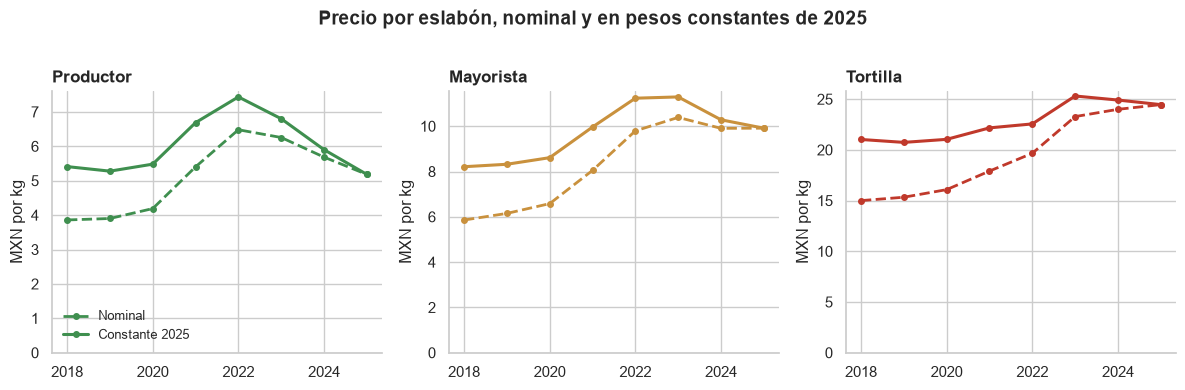

In [4]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3.8))
anios = real["anio"]
for ax, e in zip(axs, ESLABONES):
    ax.plot(anios, real[e], color=COLORES[e], lw=2, ls="--", marker="o", ms=4, label="Nominal")
    ax.plot(anios, real[f"{e}_real"], color=COLORES[e], lw=2.2, marker="o", ms=4, label="Constante 2025")
    ax.set_title(ETIQUETAS[e], loc="left"); ax.set_xticks(anios[::2]); ax.set_ylabel("MXN por kg")
    ax.set_ylim(0, None)
axs[0].legend(frameon=False, fontsize=9)
fig.suptitle("Precio por eslabón, nominal y en pesos constantes de 2025", fontweight="bold", y=1.02)
plt.tight_layout(); guardar(fig, "cadena_real"); plt.show()

## 4 | Transmisión: subida 2020 → 2023 y bajada 2023 → 2025

Cambio porcentual de cada eslabón en cada fase, en pesos corrientes y en pesos constantes. La última columna es la inflación general promedio de la misma fase.

In [5]:
c_nom = cadena[["anio", *ESLABONES]]
c_real = real[["anio", *[f"{e}_real" for e in ESLABONES]]].rename(columns=lambda c: c.replace("_real", ""))
t_nom = transmision_asimetrica(c_nom, base=BASE, pico=PICO, final=FINAL).set_index("eslabon")
t_rea = transmision_asimetrica(c_real, base=BASE, pico=PICO, final=FINAL).set_index("eslabon")
infl_sub = (ipc_anual[PICO] / ipc_anual[BASE] - 1) * 100
infl_baj = (ipc_anual[FINAL] / ipc_anual[PICO] - 1) * 100
H.update(infl_sub=infl_sub, infl_baj=infl_baj)

comp = pd.DataFrame({
    "subida_nominal_pct": t_nom["subida_pct"], "subida_real_pct": t_rea["subida_pct"],
    "bajada_nominal_pct": t_nom["bajada_pct"], "bajada_real_pct": t_rea["bajada_pct"],
    "revertido_nominal_pct": t_nom["pct_subida_revertido"], "revertido_real_pct": t_rea["pct_subida_revertido"],
})
display(comp.round(1))
display(Markdown(
    f"Inflación general (promedio anual del INPC): **+{infl_sub:.1f} %** de {BASE} a {PICO} y **+{infl_baj:.1f} %** de {PICO} a {FINAL}."
))
H["comp"] = comp

,subida_nominal_pct,subida_real_pct,bajada_nominal_pct,bajada_real_pct,revertido_nominal_pct,revertido_real_pct
eslabon,,,,,,
productor,49.3,24.1,-17.2,-23.8,52.0,122.6
mayorista,57.8,31.1,-4.6,-12.2,12.5,51.5
tortilla,44.8,20.3,5.1,-3.4,-16.4,19.9


Inflación general (promedio anual del INPC): **+20.3 %** de 2020 a 2023 y **+8.7 %** de 2023 a 2025.

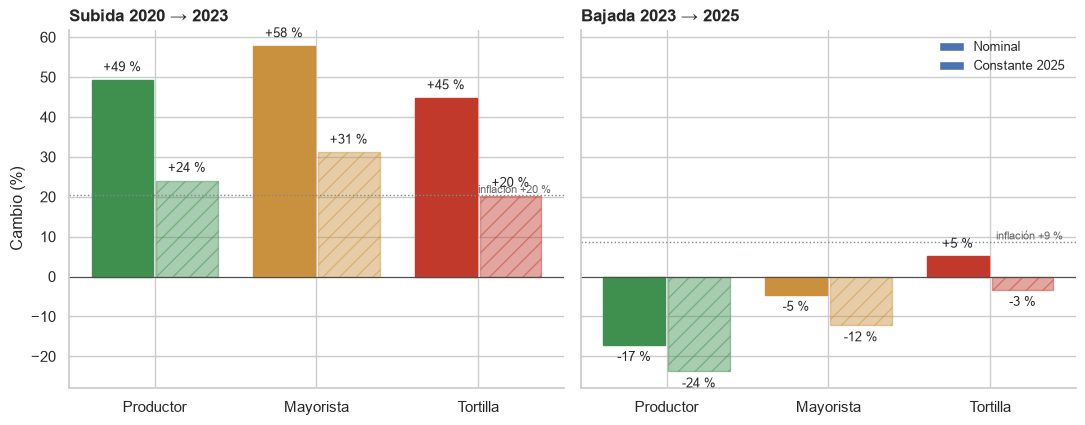

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
for ax, fase, ini, fin, infl in [(axs[0], "subida", BASE, PICO, infl_sub), (axs[1], "bajada", PICO, FINAL, infl_baj)]:
    for i, e in enumerate(ESLABONES):
        for dx, col, alpha, hatch, nombre in [(-0.2, "nominal", 1, None, "Nominal"), (0.2, "real", 0.45, "//", "Constante")]:
            v = comp.loc[e, f"{fase}_{col}_pct"]
            ax.bar(i + dx, v, 0.38, color=COLORES[e], alpha=alpha, hatch=hatch, edgecolor=COLORES[e])
            ax.text(i + dx, v + (1.5 if v >= 0 else -1.5), f"{v:+.0f} %", ha="center", va="bottom" if v >= 0 else "top", fontsize=9)
    ax.axhline(0, color="0.3", lw=0.8)
    ax.axhline(infl, color=GRIS, lw=1, ls=":")
    ax.text(2.45, infl, f"inflación {infl:+.0f} %", color="0.4", fontsize=8, va="bottom", ha="right")
    ax.set_xticks(range(3), [ETIQUETAS[e] for e in ESLABONES])
    ax.set_title(f"{fase.capitalize()} {ini} → {fin}", loc="left")
axs[0].set_ylabel("Cambio (%)")
axs[1].bar([], [], color="0.4", label="Nominal"); axs[1].bar([], [], color="0.4", alpha=0.45, hatch="//", label="Constante 2025")
axs[1].legend(frameon=False, loc="upper right", fontsize=9)
plt.tight_layout(); guardar(fig, "transmision"); plt.show()

## 5 | Tortilla PROFECO frente a la inflación general

Precio nacional mensual de la tortilla en tortillerías y el INPC, ambos con promedio de 2020 = 100. Si la línea de la tortilla queda por encima del INPC, la tortilla subió más que los precios en general.

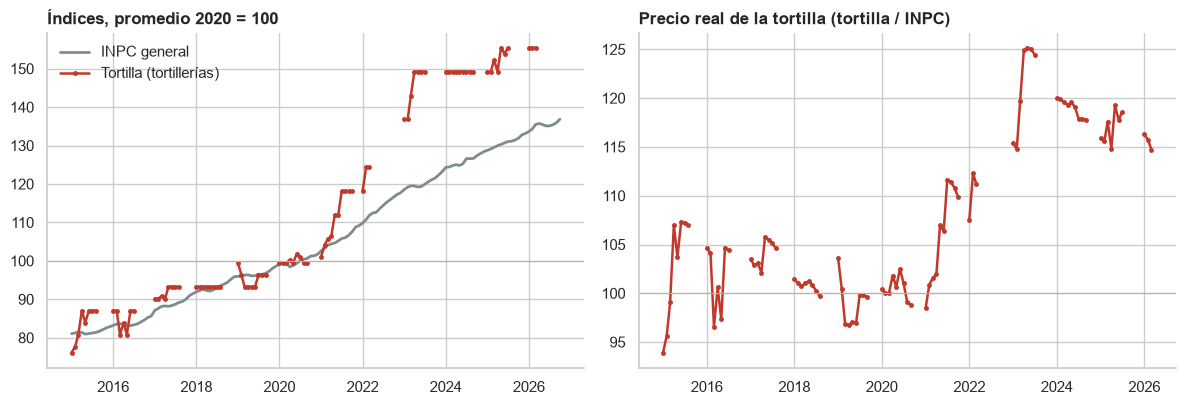

,tortilla_nominal_pct,inpc_pct,tortilla_real_pct
2018→2025,63.1,40.2,16.3
2020→2025,52.1,30.8,16.3
2020→2023,44.8,20.3,20.3
2023→2025,5.1,8.7,-3.4


De 2020 a 2025 la tortilla subió **52 %** nominal y el INPC 31 %: en términos reales **+16.3 %**. Desde 2018: 63 % nominal, +16.3 % real. Los promedios anuales usan solo los meses con precio de cada año.

In [7]:
r20 = tort.loc["2020"].mean(), inpc.loc["2020", "indice"].mean()
t_idx = tort / r20[0] * 100
i_idx = inpc["indice"] / r20[1] * 100
ambos = pd.DataFrame({"tortilla": t_idx, "inpc": i_idx}).sort_index().loc["2015":]
ambos["real"] = ambos["tortilla"] / ambos["inpc"] * 100

fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
axs[0].plot(ambos.index, ambos["inpc"], color=GRIS, lw=2, label="INPC general")
axs[0].plot(ambos.index, ambos["tortilla"], color=COLORES["tortilla"], lw=1.8, marker="o", ms=2.5, label="Tortilla (tortillerías)")
axs[0].axhline(100, color="0.7", lw=0.8)
axs[0].set_title("Índices, promedio 2020 = 100", loc="left"); axs[0].legend(frameon=False)
axs[1].plot(ambos.index, ambos["real"], color=COLORES["tortilla"], lw=1.8, marker="o", ms=2.5)
axs[1].axhline(100, color="0.7", lw=0.8)
axs[1].set_title("Precio real de la tortilla (tortilla / INPC)", loc="left")
for ax in axs:
    ax.xaxis.set_major_locator(mdates.YearLocator(2)); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.tight_layout(); guardar(fig, "tortilla_vs_inpc"); plt.show()

def cambio(ini, fin):
    a, b = ambos.loc[str(ini), "tortilla"].mean(), ambos.loc[str(fin), "tortilla"].mean()
    ia, ib = ipc_anual[ini], ipc_anual[fin]
    return pd.Series({"tortilla_nominal_pct": (b / a - 1) * 100, "inpc_pct": (ib / ia - 1) * 100,
                      "tortilla_real_pct": ((b / a) / (ib / ia) - 1) * 100})
vent = pd.DataFrame({f"{a}→{b}": cambio(a, b) for a, b in [(2018, 2025), (2020, 2025), (2020, 2023), (2023, 2025)]}).T
display(vent.round(1))
H["vent"] = vent
display(Markdown(
    f"De 2020 a 2025 la tortilla subió **{vent.loc['2020→2025', 'tortilla_nominal_pct']:.0f} %** nominal y el INPC {vent.loc['2020→2025', 'inpc_pct']:.0f} %: "
    f"en términos reales **{vent.loc['2020→2025', 'tortilla_real_pct']:+.1f} %**. "
    f"Desde 2018: {vent.loc['2018→2025', 'tortilla_nominal_pct']:.0f} % nominal, {vent.loc['2018→2025', 'tortilla_real_pct']:+.1f} % real. "
    "Los promedios anuales usan solo los meses con precio de cada año."
))

### 5.1 | Gruma en términos reales (referencia breve)

Rendimiento anual de Gruma (`GRUMAB.MX`, columna `rendimiento_gruma` de la cadena anual) descontando la inflación de diciembre a diciembre: (1 + r) / (1 + π) − 1.

In [8]:
g = pd.read_csv(raiz / "data/processed/cadena_maiz_anual.csv").set_index("anio")["rendimiento_gruma"] * 100
pi_dic = inpc[inpc.index.month == 12].set_index(inpc[inpc.index.month == 12].index.year)["var_anual_pct"]
gr = pd.DataFrame({"gruma_nominal_pct": g, "inflacion_dic_pct": pi_dic.reindex(g.index)})
gr["gruma_real_pct"] = ((1 + gr["gruma_nominal_pct"] / 100) / (1 + gr["inflacion_dic_pct"] / 100) - 1) * 100
display(gr.loc[2018:2025].round(1))
H["gr"] = gr

,gruma_nominal_pct,inflacion_dic_pct,gruma_real_pct
anio,,,
2018,-9.0,4.8,-13.2
2019,-10.3,2.8,-12.8
2020,24.3,3.2,20.5
2021,12.7,7.4,5.0
2022,2.6,7.8,-4.9
2023,21.7,4.7,16.3
2024,6.2,4.2,1.9
2025,-4.0,3.7,-7.4


## 6 | Síntesis

In [9]:
c, r = H["comp"], H["comp"]
nom, rea = t_nom, t_rea
ro = real.set_index("anio")
# El orden de la bajada es el que sustentan las afirmaciones del texto.
assert rea.loc["productor", "bajada_pct"] < rea.loc["mayorista", "bajada_pct"] < rea.loc["tortilla", "bajada_pct"] < 0
assert rea.loc["productor", "pct_subida_revertido"] > 100 > rea.loc["mayorista", "pct_subida_revertido"] > rea.loc["tortilla", "pct_subida_revertido"] > 0
v = H["vent"]
display(Markdown(
    "**¿Cambian las conclusiones de la Historia 1?** La dirección no cambia; la magnitud sí.\n\n"
    f"1. **Parte de la subida nominal era inflación.** De {BASE} a {PICO} el INPC subió {H['infl_sub']:.0f} %. "
    f"En pesos constantes la subida fue {rea.loc['productor', 'subida_pct']:.0f} % en el productor "
    f"(nominal {nom.loc['productor', 'subida_pct']:.0f} %), {rea.loc['mayorista', 'subida_pct']:.0f} % en el mayorista "
    f"({nom.loc['mayorista', 'subida_pct']:.0f} %) y {rea.loc['tortilla', 'subida_pct']:.0f} % en la tortilla ({nom.loc['tortilla', 'subida_pct']:.0f} %). "
    "El orden entre eslabones se mantiene y el choque sigue siendo general.\n"
    f"2. **La bajada llega al campo, cada vez menos arriba.** De {PICO} a {FINAL} el productor cae {abs(rea.loc['productor', 'bajada_pct']):.0f} % real "
    f"(nominal {nom.loc['productor', 'bajada_pct']:.0f} %), el mayorista {abs(rea.loc['mayorista', 'bajada_pct']):.0f} % "
    f"({nom.loc['mayorista', 'bajada_pct']:.0f} %) y la tortilla {abs(rea.loc['tortilla', 'bajada_pct']):.0f} % "
    f"(nominal {nom.loc['tortilla', 'bajada_pct']:+.0f} %). Es el mismo gradiente que en la Historia 1.\n"
    f"3. **Lo que sí cambia es la lectura de la bajada.** Nominalmente la tortilla no bajó (+{nom.loc['tortilla', 'bajada_pct']:.0f} %); en términos reales cedió "
    f"{abs(rea.loc['tortilla', 'bajada_pct']):.0f} %, porque la inflación general fue {H['infl_baj']:.0f} % en esos años. "
    f"El productor revierte {rea.loc['productor', 'pct_subida_revertido']:.0f} % de su alza real: en 2025 recibe ${ro.loc[2025, 'productor_real']:.2f}/kg "
    f"frente a ${ro.loc[BASE, 'productor_real']:.2f} en {BASE} (pesos de 2025). El mayorista revierte {rea.loc['mayorista', 'pct_subida_revertido']:.0f} % y la tortilla {rea.loc['tortilla', 'pct_subida_revertido']:.0f} %.\n"
    f"4. **La tortilla sí subió más que la inflación.** De 2020 a 2025 subió {v.loc['2020→2025', 'tortilla_nominal_pct']:.0f} % nominal frente a {v.loc['2020→2025', 'inpc_pct']:.0f} % del INPC "
    f"({v.loc['2020→2025', 'tortilla_real_pct']:+.0f} % real). En 2025 sigue {v.loc['2020→2025', 'tortilla_real_pct']:.0f} % arriba de su nivel real de 2020, "
    f"el mayorista {(ro.loc[2025, 'mayorista_real'] / ro.loc[BASE, 'mayorista_real'] - 1) * 100:.0f} % y el productor {(ro.loc[2025, 'productor_real'] / ro.loc[BASE, 'productor_real'] - 1) * 100:+.0f} %.\n"
    f"5. **Gruma.** Su rendimiento real fue {H['gr'].loc[2023, 'gruma_real_pct']:.0f} % en 2023 y {H['gr'].loc[2025, 'gruma_real_pct']:.0f} % en 2025; la inflación general lo reduce en {H['gr'].loc[2023, 'inflacion_dic_pct']:.1f} y {H['gr'].loc[2025, 'inflacion_dic_pct']:.1f} puntos. "
    "\n\n"
    "**Limitaciones.** Se deflacta con el INPC general, no con un índice de alimentos. "
    "Los promedios anuales de tortilla se basan en 3 a 10 meses según el año. Las cifras de la Historia 1 en pesos corrientes se reproducen aquí sin cambios."
))

**¿Cambian las conclusiones de la Historia 1?** La dirección no cambia; la magnitud sí.

1. **Parte de la subida nominal era inflación.** De 2020 a 2023 el INPC subió 20 %. En pesos constantes la subida fue 24 % en el productor (nominal 49 %), 31 % en el mayorista (58 %) y 20 % en la tortilla (45 %). El orden entre eslabones se mantiene y el choque sigue siendo general.
2. **La bajada llega al campo, cada vez menos arriba.** De 2023 a 2025 el productor cae 24 % real (nominal -17 %), el mayorista 12 % (-5 %) y la tortilla 3 % (nominal +5 %). Es el mismo gradiente que en la Historia 1.
3. **Lo que sí cambia es la lectura de la bajada.** Nominalmente la tortilla no bajó (+5 %); en términos reales cedió 3 %, porque la inflación general fue 9 % en esos años. El productor revierte 123 % de su alza real: en 2025 recibe $5.18/kg frente a $5.48 en 2020 (pesos de 2025). El mayorista revierte 51 % y la tortilla 20 %.
4. **La tortilla sí subió más que la inflación.** De 2020 a 2025 subió 52 % nominal frente a 31 % del INPC (+16 % real). En 2025 sigue 16 % arriba de su nivel real de 2020, el mayorista 15 % y el productor -5 %.
5. **Gruma.** Su rendimiento real fue 16 % en 2023 y -7 % en 2025; la inflación general lo reduce en 4.7 y 3.7 puntos. 

**Limitaciones.** Se deflacta con el INPC general, no con un índice de alimentos. Los promedios anuales de tortilla se basan en 3 a 10 meses según el año. Las cifras de la Historia 1 en pesos corrientes se reproducen aquí sin cambios.